# TP6 — Piloter un LLM depuis du code : classer des critiques de films (Correction)

Cours associé : [TP6_Cours.md](TP6_Cours.md) · Modèle local (facultatif) : [Installer_Ollama.md](../Installer_Ollama.md)

## Contexte

Un site de cinéma reçoit chaque jour des milliers de critiques écrites par ses membres. Il souhaite les classer automatiquement (positives ou négatives) et en extraire les points forts et les points faibles des films. Vous testez une solution à base de **grand modèle de langage** (LLM), appelé depuis Python, et vous la comparez à un modèle d'apprentissage automatique classique.

Le dossier `data/` contient des critiques du site Allociné :

| Fichier | Contenu |
|---|---|
| `allocine_train.csv` | 5 000 critiques étiquetées, pour entraîner le modèle classique |
| `allocine_test.csv` | 50 critiques courtes étiquetées, pour évaluer les deux approches |

Chaque fichier a deux colonnes : `critique` (le texte) et `sentiment` (`positif` ou `négatif`).

## Avant de commencer

**1. Les bibliothèques.** Dans l'environnement du cours :

```bash
uv pip install openai python-dotenv pydantic
```

ou, avec Conda :

```bash
conda install -c conda-forge openai python-dotenv pydantic
```

**2. Une clé d'API Mistral.** Sur [console.mistral.ai](https://console.mistral.ai), créez un compte, choisissez l'offre gratuite d'expérimentation (*Experiment*), puis créez une clé dans la rubrique *API Keys*. Copiez-la tout de suite : elle ne sera plus affichée.

**3. Le fichier `.env`.** Dans le dossier de ce TP, créez un fichier texte nommé `.env` (avec le point) contenant :

```bash
LLM_BASE_URL=https://api.mistral.ai/v1
LLM_API_KEY=collez-votre-clé-ici
LLM_MODEL=ministral-8b-latest
```

> ⚠️ Votre clé est **personnelle et secrète** : ne l'écrivez jamais dans le notebook, ne la partagez pas, ne publiez pas le fichier `.env` (ajoutez `.env` à votre `.gitignore`).

> 💡 Sans compte Mistral, vous pouvez faire tout le TP avec un modèle installé sur votre ordinateur : suivez [Installer_Ollama.md](../Installer_Ollama.md) et changez les trois lignes du `.env`. Les réponses seront moins bonnes et plus lentes.

## Déroulé

| Partie | Contenu |
|---|---|
| 1 | Premier appel : messages, rôles et absence de mémoire |
| 2 | Tokens et coût |
| 3 | La température |
| 4 | Ingénierie de prompt |
| 5 | Sorties structurées avec Pydantic |
| 6 | Évaluer le LLM et le comparer à un modèle classique |
| 7 | *Facultatif* : few-shot, autres modèles, extraction d'information |

Les cellules marquées `# TODO` sont à compléter. Les cellules ✍️ attendent une réponse rédigée.

Les réponses d'un LLM **varient** d'un appel à l'autre et d'une version du modèle à l'autre : ne vous étonnez pas d'obtenir des formulations différentes de celles de votre voisin.

In [1]:
import os
import time
from typing import Literal

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from openai import OpenAI, RateLimitError
from pydantic import BaseModel, Field

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

load_dotenv()  # lit le fichier .env : la clé n'apparaît jamais dans le notebook
client = OpenAI(base_url=os.environ["LLM_BASE_URL"], api_key=os.environ["LLM_API_KEY"])
MODELE = os.environ["LLM_MODEL"]
print("Modèle utilisé :", MODELE)

Modèle utilisé : ministral-8b-latest


La fonction `appeler` ci-dessous est **fournie**. Elle fait la même chose que `client.chat.completions.create` (ou `client.chat.completions.parse` quand on lui donne un schéma `response_format`, partie 5), mais si l'API répond que vous envoyez trop de requêtes (erreur 429, fréquente quand toute la classe travaille en même temps), elle attend quelques secondes et réessaie. Lisez-la, puis exécutez la cellule.

In [2]:
def appeler(messages, modele=None, response_format=None, **parametres):
    """Envoie une liste de messages au modèle et renvoie la réponse complète de l'API.
    Avec un schéma Pydantic en response_format, la réponse est une sortie structurée (partie 5).
    Les paramètres supplémentaires (temperature, max_tokens…) sont transmis tels quels."""
    for essai in range(7):
        try:
            if response_format is None:
                return client.chat.completions.create(model=modele or MODELE, messages=messages, **parametres)
            return client.chat.completions.parse(model=modele or MODELE, messages=messages,
                                                 response_format=response_format, **parametres)
        except RateLimitError:
            attente = 2 ** essai
            print(f"Trop de requêtes : nouvel essai dans {attente} s")
            time.sleep(attente)
    raise RuntimeError("Limite de débit toujours dépassée : réessayez dans une minute.")

## Partie 1 — Premier appel : messages, rôles et absence de mémoire

**1.1** Appelez le modèle avec deux messages :
- un message `system` : « Tu es un assistant de l'IUT. Tu réponds en deux phrases au maximum. » ;
- un message `user` : « Qu'est-ce qu'un jeu de test en apprentissage automatique ? ».

Utilisez `temperature=0.2` et `max_tokens=150`. Affichez le texte de la réponse, la raison de l'arrêt (`finish_reason`) et la consommation de tokens (`usage`).

In [3]:
# TODO : premier appel au modèle
reponse = appeler(
    [{"role": "system", "content": "Tu es un assistant de l'IUT. Tu réponds en deux phrases au maximum."},
     {"role": "user", "content": "Qu'est-ce qu'un jeu de test en apprentissage automatique ?"}],
    temperature=0.2, max_tokens=150)
print(reponse.choices[0].message.content)
print("arrêt :", reponse.choices[0].finish_reason)
print("tokens envoyés :", reponse.usage.prompt_tokens, "| tokens reçus :", reponse.usage.completion_tokens)

Un **jeu de test** (*test set*) en apprentissage automatique est un sous-ensemble des données **non utilisé pour l'entraînement** du modèle, réservé à évaluer sa performance finale.

Il permet d'estimer la généralisation du modèle sur des données inconnues, sans biais lié à l'entraînement.
arrêt : stop
tokens envoyés : 36 | tokens reçus : 66


**1.2** Relancez le même appel avec `max_tokens=10`. Que devient la réponse ? Que vaut `finish_reason` ?

In [4]:
# TODO : même appel avec max_tokens=10
reponse = appeler(
    [{"role": "system", "content": "Tu es un assistant de l'IUT. Tu réponds en deux phrases au maximum."},
     {"role": "user", "content": "Qu'est-ce qu'un jeu de test en apprentissage automatique ?"}],
    temperature=0.2, max_tokens=10)
print(reponse.choices[0].message.content)
print("arrêt :", reponse.choices[0].finish_reason)

Un **jeu de test** (*test set
arrêt : length


✅ **Éléments de réponse**

- En 1.1, la réponse est complète, en une ou deux phrases comme demandé dans le message `system`, et `finish_reason` vaut `"stop"` : le modèle a terminé de lui-même. `usage` indique quelques dizaines de tokens envoyés (36 avec `ministral-8b-latest`) et quelques dizaines de tokens reçus (entre 50 et 80 selon les exécutions) : c'est ce qui serait facturé.
- Avec `max_tokens=10`, la réponse est **coupée au milieu d'une phrase** et `finish_reason` vaut `"length"`. `max_tokens` ne demande pas au modèle d'être bref : il **interrompt** la génération. Pour une réponse courte, il faut le demander dans le prompt ; `max_tokens` sert de garde-fou contre les dépenses. Un programme doit vérifier `finish_reason` avant d'utiliser une réponse.

**1.3** Le modèle a-t-il une mémoire ? Faites **deux appels séparés** :
1. un message `user` : « Je m'appelle Léa et j'étudie l'informatique à Belfort. » ;
2. puis, dans un nouvel appel, un message `user` : « Comment je m'appelle et dans quelle ville j'étudie ? ».

Faites ensuite un **troisième appel** dont la liste `messages` contient tout l'échange : le premier message, la réponse du modèle (rôle `assistant`), puis la question.

In [5]:
# TODO : deux appels séparés, puis un appel avec l'historique
presentation = {"role": "user", "content": "Je m'appelle Léa et j'étudie l'informatique à Belfort."}
question = {"role": "user", "content": "Comment je m'appelle et dans quelle ville j'étudie ?"}

r1 = appeler([presentation], temperature=0, max_tokens=100)
print("1 :", r1.choices[0].message.content, "\n")
r2 = appeler([question], temperature=0, max_tokens=100)
print("2 :", r2.choices[0].message.content, "\n")

historique = [presentation, {"role": "assistant", "content": r1.choices[0].message.content}, question]
r3 = appeler(historique, temperature=0, max_tokens=100)
print("3 :", r3.choices[0].message.content)

1 : Salut Léa ! 😊
C’est super que tu étudies l’informatique à Belfort – une ville avec une belle histoire industrielle et un bon écosystème tech (notamment grâce à des acteurs comme **Sopra Steria**, **Atos** ou des startups locales). Tu es dans quel domaine précis en ce moment ? Développement web, IA, cybersécurité, data, etc. ?

Si tu cherches des ressources, des conseils pour 



2 : Je ne connais pas ton nom ni la ville où tu étudies, car je n'ai pas accès à tes informations personnelles.

Si tu veux me donner ces détails (ou d'autres informations), je pourrai t'aider avec plaisir ! 😊

*(Par exemple : "Je m'appelle [TonPrénom] et j'étudie à [Ville].")*

Tu veux que je t'aide pour autre chose en lien avec tes études ? 



3 : Tu t’appelles **Léa** et tu étudies **l’informatique à Belfort** ! 😊

*(Petit rappel pour toi : si tu veux partager ton parcours ou tes projets, je suis là pour t’aider !)* 🚀

Tu veux parler de tes cours, de tes passions tech ou de la vie étudiante à Belfort ? 😄


✅ **Éléments de réponse**

- Au premier appel, le modèle répond avec enthousiasme, et parfois en inventant des détails sur Belfort. Au deuxième appel, il **ne sait pas** comment vous vous appelez : il le dit, et vous propose de le lui indiquer. Chaque appel est indépendant ; le modèle est **sans état**.
- Au troisième appel, il répond correctement « Léa » et « Belfort », simplement parce que l'information est **dans les messages envoyés**.
- C'est donc le **programme** qui donne l'illusion d'une conversation, en renvoyant tout l'historique à chaque tour, comme le fait l'application ChatGPT.

**1.4** Écrivez une fonction `discuter(message)` qui ajoute le message de l'utilisateur à une liste globale `conversation`, appelle le modèle avec toute la liste, ajoute la réponse (rôle `assistant`) à la liste, et renvoie le texte de la réponse avec le nombre de tokens envoyés. Commencez la conversation par un message `system` de votre choix et faites trois tours de dialogue. Comment évolue le nombre de tokens envoyés ?

In [6]:
# TODO : un mini-chatbot avec historique
conversation = [{"role": "system", "content": "Tu es un critique de cinéma passionné. Tu réponds en trois phrases au maximum."}]


def discuter(message):
    conversation.append({"role": "user", "content": message})
    reponse = appeler(conversation, temperature=0.3, max_tokens=200)
    texte = reponse.choices[0].message.content
    conversation.append({"role": "assistant", "content": texte})
    return texte, reponse.usage.prompt_tokens


for message in ["Conseille-moi un film de science-fiction des années 1980.",
                "Qui l'a réalisé ?",
                "Et un autre film du même réalisateur ?"]:
    texte, tokens = discuter(message)
    print(f"[{tokens} tokens envoyés] {texte}\n")

[39 tokens envoyés] *"Blade Runner"* (1982) de Ridley Scott est un chef-d'œuvre intemporel qui redéfinit la SF avec ses questions philosophiques et son esthétique cyberpunk. Son ambiance sombre et ses personnages complexes en font une expérience visuelle et narrative inoubliable. Si tu veux une alternative plus légère mais tout aussi visionnaire, *"Retour vers le futur"* (1985) est un classique hilarant et poétique.



[146 tokens envoyés] *"Blade Runner"* a été réalisé par **Ridley Scott**, tandis que *"Retour vers le futur"* est de **Robert Zemeckis**. Les deux ont marqué leur époque avec des approches radicalement différentes de la SF.



[207 tokens envoyés] **"Alien, le huitième passager" (1979)** de Ridley Scott est un chef-d'œuvre horrifique et SF, où l'atmosphère oppressante et la créature légendaire font des frissons. Son mélange de tension psychologique et de design futuriste reste inégalé. Pour un autre style, **"Prometheus" (2012)** explore des thèmes similaires avec une esthétique plus contemplative.



✅ **Éléments de réponse**

- Les questions « Qui l'a réalisé ? » et « du même réalisateur » n'ont de sens que grâce à l'historique : le modèle s'en sert pour savoir de quel film on parle.
- Vérifiez ce qu'il affirme : il arrive qu'il se trompe avec aplomb sur un réalisateur ou une date (une exécution de cette correction a attribué *Les Aventures de Buckaroo Banzai* à un mauvais réalisateur). C'est une **hallucination**.
- Le nombre de tokens envoyés **augmente à chaque tour** (d'environ 40 à environ 130 puis environ 200 lors de l'exécution de cette correction), car on renvoie toute la conversation. Une longue conversation coûte de plus en plus cher à chaque message et finit par ne plus tenir dans la **fenêtre de contexte** : les applications de discussion résument ou tronquent alors les anciens messages.

## Partie 2 — Tokens et coût

La fonction `compter_tokens` ci-dessous est fournie : elle envoie un texte au modèle en limitant la réponse à un seul token, et lit le nombre de tokens envoyés dans `usage`. Ce nombre inclut quelques tokens de mise en forme du message, toujours les mêmes.

In [7]:
def compter_tokens(texte):
    """Nombre de tokens envoyés pour un message contenant `texte` (mise en forme comprise)."""
    return compter_tokens_messages([{"role": "user", "content": texte}])


def compter_tokens_messages(messages):
    """Nombre de tokens envoyés pour une liste de messages complète."""
    return appeler(messages, max_tokens=1).usage.prompt_tokens

**2.1** Comptez les tokens des textes suivants et calculez, pour chacun, le nombre de caractères par token :
- « Le modèle de langage prédit le mot suivant. » ;
- sa traduction : « The language model predicts the next word. » ;
- « Le modele de langaje predi le mo suivan. » (la même phrase avec des fautes) ;
- « 3,14159265358979323846 ».

Que constatez-vous ?

In [8]:
# TODO : tokens et caractères par token
textes = ["Le modèle de langage prédit le mot suivant.",
          "The language model predicts the next word.",
          "Le modele de langaje predi le mo suivan.",
          "3,14159265358979323846"]
resultats = pd.DataFrame({"texte": textes,
                          "caractères": [len(t) for t in textes],
                          "tokens": [compter_tokens(t) for t in textes]})
resultats["caractères par token"] = (resultats["caractères"] / resultats["tokens"]).round(1)
resultats

,texte,caractères,tokens,caractères par token
0,Le modèle de langage prédit le mot suivant.,43,13,3.3
1,The language model predicts the next word.,42,11,3.8
2,Le modele de langaje predi le mo suivan.,40,16,2.5
3,"3,14159265358979323846",22,25,0.9


✅ **Éléments de réponse**

*(Les comptes dépendent du modèle ; avec `ministral-8b-latest`, on obtient 13 tokens pour la phrase française, 11 pour l'anglaise, 16 pour la phrase avec des fautes et 25 pour le nombre, mise en forme comprise.)*

- La phrase anglaise demande **moins de tokens** que la phrase française de même sens : le découpage en tokens est optimisé pour l'anglais, majoritaire dans les données d'entraînement. Le même service coûte donc un peu plus cher en français.
- La phrase **avec des fautes** coûte plus de tokens que la phrase correcte : les mots mal orthographiés sont rares, le découpage les coupe en petits morceaux.
- Les **chiffres** sont très mal compressés (environ un token par chiffre, soit moins d'un caractère par token en comptant la mise en forme) : les nombres longs coûtent cher, et le modèle les « voit » morceau par morceau, ce qui explique en partie ses erreurs de calcul.

**2.2** Chargez `data/allocine_test.csv` dans `test`. Prenez la critique la plus longue, comptez ses tokens et déduisez-en le nombre moyen de caractères par token pour du texte français ordinaire. Estimez ensuite le nombre de tokens d'une critique moyenne de `test`.

In [9]:
# TODO : tokens d'une critique
test = pd.read_csv("data/allocine_test.csv")
longue = test.loc[test["critique"].str.len().idxmax(), "critique"]
n_tokens = compter_tokens(longue)
car_par_token = len(longue) / n_tokens
print(f"{len(longue)} caractères, {n_tokens} tokens, soit {car_par_token:.1f} caractères par token")
tokens_moyens = test["critique"].str.len().mean() / car_par_token
print(f"une critique moyenne fait environ {tokens_moyens:.0f} tokens")

294 caractères, 74 tokens, soit 4.0 caractères par token
une critique moyenne fait environ 48 tokens


**2.3** On veut classer les 20 000 critiques reçues chaque mois. Chaque appel envoie la critique plus une consigne d'environ 60 tokens, et reçoit une réponse d'environ 5 tokens. Calculez le coût mensuel avec les deux tarifs ci-dessous (indicatifs, novembre 2026, en dollars par million de tokens).

In [10]:
TARIFS = {  # (prix d'un million de tokens envoyés, prix d'un million de tokens reçus), en $
    "ministral-8b-latest (petit modèle)": (0.15, 0.15),
    "mistral-large-latest (grand modèle)": (0.50, 1.50),
}

In [11]:
# TODO : coût mensuel selon le modèle
N_CRITIQUES, CONSIGNE, SORTIE = 20_000, 60, 5
for nom, (prix_entree, prix_sortie) in TARIFS.items():
    entree = N_CRITIQUES * (CONSIGNE + tokens_moyens)
    sortie = N_CRITIQUES * SORTIE
    cout = entree / 1e6 * prix_entree + sortie / 1e6 * prix_sortie
    print(f"{nom} : {entree / 1e6:.2f} M tokens envoyés, coût ≈ {cout:.2f} $ par mois")

ministral-8b-latest (petit modèle) : 2.15 M tokens envoyés, coût ≈ 0.34 $ par mois
mistral-large-latest (grand modèle) : 2.15 M tokens envoyés, coût ≈ 1.23 $ par mois


✅ **Éléments de réponse**

- La critique la plus longue (294 caractères) fait 74 tokens, soit environ 4 caractères par token ; une critique moyenne du jeu de test fait donc une cinquantaine de tokens. Avec la consigne, chaque appel envoie environ 110 tokens, et le mois entier environ 2,2 millions de tokens.
- Le coût est d'environ **0,3 $ par mois** avec le petit modèle et d'environ **1,2 $** avec le grand : dans les deux cas, c'est négligeable. Ce sont surtout les **tokens envoyés** qui comptent, car la réponse est très courte.
- Le calcul change d'échelle avec de longs documents (un contrat de 50 pages), un historique de conversation renvoyé à chaque message (partie 1) ou des millions d'utilisateurs : d'où l'intérêt de prompts courts et d'un modèle aussi petit que possible.

## Partie 3 — La température

**3.1** Demandez cinq fois au modèle : « Propose un nom pour une application de covoiturage entre étudiants. Réponds uniquement par le nom. », d'abord avec `temperature=0`, puis avec `temperature=1.2` (`max_tokens=15`). Comparez.

In [12]:
# TODO : même demande, deux températures
demande = [{"role": "user", "content": "Propose un nom pour une application de covoiturage entre étudiants. Réponds uniquement par le nom."}]
for temperature in [0, 1.2]:
    noms = [appeler(demande, temperature=temperature, max_tokens=15).choices[0].message.content.strip()
            for _ in range(5)]
    print(f"température {temperature} : {noms}")

température 0 : ['**ShareRide Campus**', '**ShareRide Campus**', '**ShareRide Campus**', '**ShareRide Campus**', '**ShareRide Campus**']


température 1.2 : ['**StudoRide**', '**PasseColle**', '**PasseToi**', '**EtudeRide**', '**ShareRide Campus**']


✅ **Éléments de réponse**

- À température 0, les cinq réponses sont **identiques** ou presque : le modèle prend chaque fois le mot le plus probable. (Il arrive que deux réponses diffèrent légèrement : les calculs du serveur ne sont pas parfaitement déterministes.)
- À température 1,2, les noms sont **presque tous différents** : le modèle tire au sort parmi les mots plausibles. C'est ce qu'on veut pour trouver des idées ; certaines propositions sont moins heureuses.
- Remarquez aussi que le modèle met souvent le nom **en gras** (`**…**`) alors qu'on lui demandait « uniquement le nom » : les modèles de discussion sont entraînés à produire du Markdown. Un programme qui utilise la réponse doit s'y attendre (partie 4).

**3.2** Pour classer des critiques en positif ou négatif, quelle température choisir ? Et pour écrire automatiquement un résumé accrocheur de chaque film ? Justifiez.

✅ **Éléments de réponse**

- Pour **classer**, une température de **0** : on veut que la même critique reçoive toujours la même étiquette, et que les mesures de la partie 6 soient aussi reproductibles que possible. La créativité n'apporte rien, elle ne fait qu'ajouter des erreurs au hasard.
- Pour **rédiger** un résumé accrocheur, une température moyenne (0,5 à 0,8) : un peu de variété rend les textes moins répétitifs d'un film à l'autre, sans tomber dans l'incohérence.

## Partie 4 — Ingénierie de prompt

**4.1** Posez au modèle la question « Qu'est-ce qu'un token ? » (`temperature=0`, `max_tokens=80`), sans message `system`. Posez-la ensuite avec un message `system` qui lui donne un rôle adapté à ce cours. Comparez les deux réponses.

In [13]:
# TODO : la même question, sans puis avec un rôle
question = {"role": "user", "content": "Qu'est-ce qu'un token ? Réponds en une phrase."}
sans_role = appeler([question], temperature=0, max_tokens=80)
print("sans rôle :", sans_role.choices[0].message.content, "\n")
role = {"role": "system", "content": "Tu es enseignant en intelligence artificielle et tu t'adresses à des étudiants en informatique qui découvrent les grands modèles de langage."}
avec_role = appeler([role, question], temperature=0, max_tokens=80)
print("avec rôle :", avec_role.choices[0].message.content)

sans rôle : Un **token** est une unité numérique représentant un actif, un droit d'accès ou une preuve de valeur (comme une cryptomonnaie, un NFT ou un jeton de gouvernance) sur une blockchain ou une plateforme décentralisée. 



avec rôle : Un **token** est une unité de base de texte (mot, sous-mot, symbole ou caractère) que les grands modèles de langage divisent et encode pour traiter et générer du contenu de manière cohérente.


✅ **Éléments de réponse**

- Sans contexte, « token » est **ambigu** : selon le modèle, la réponse parle d'un jeton de cryptomonnaie ou de blockchain, d'un jeton d'authentification, ou d'un morceau de texte. Avec `ministral-8b-latest`, elle part sur la cryptomonnaie et la blockchain.
- Avec le rôle d'enseignant en IA, la réponse porte sur le **morceau de texte** manipulé par un modèle de langage, au bon niveau pour des étudiants.
- Le modèle ne connaît que ce que contient le prompt : tout ce qui est évident pour vous (le contexte du cours, le public, le niveau de détail) doit être **écrit**.

**4.2** Voici une critique du jeu de test. Demandez au modèle de l'analyser avec un prompt **vague** : « Que penses-tu de cette critique ? » suivi de la critique. Écrivez ensuite un prompt **précis** qui :
- donne un rôle au modèle (message `system`) ;
- indique la tâche et les **seules réponses possibles** (`positif` ou `négatif`) ;
- place la critique entre des balises `<critique>` et `</critique>` ;
- demande de répondre **par un seul mot**.

Comparez les deux réponses : laquelle un programme pourrait-il utiliser ?

In [14]:
critique = test.loc[test["critique"].str.startswith("Un nouveau film sur la mafia"), "critique"].iloc[0]
print(critique)

Un nouveau film sur la mafia. Un jeune flic infiltré(Depp) intègre puis se noie dans une organisation mafieuse. Ca manque de rythme et malgré quelques scènes réussies, l'ensemble est décevant. Al Pacino est excellent comme souvent.


In [15]:
# TODO : prompt vague, puis prompt précis
vague = appeler([{"role": "user", "content": f"Que penses-tu de cette critique ?\n{critique}"}],
                temperature=0, max_tokens=300)
print("VAGUE :", vague.choices[0].message.content, "\n")

precis = appeler([
    {"role": "system", "content": "Tu es un modérateur de critiques de cinéma. Tu classes chaque critique selon l'avis de son auteur sur le film."},
    {"role": "user", "content": "Classe la critique ci-dessous. Réponds uniquement par un mot : positif ou négatif.\n"
                                f"<critique>\n{critique}\n</critique>"}],
    temperature=0, max_tokens=5)
print("PRÉCIS :", precis.choices[0].message.content)

VAGUE : Ta critique est **équilibrée et pertinente**, et elle touche à des points clés qui peuvent expliquer les limites (et les forces) de ce type de film. Voici une analyse détaillée, avec quelques pistes pour affiner ton jugement ou le contextualiser :

---

### **1. Le rythme : un écueil fréquent dans les films de mafia**
- **Problème récurrent** : Les films sur la mafia (surtout ceux inspirés de *Le Parrain* ou des récits de Donnie Brasco) ont souvent tendance à **s’enliser dans des dialogues lents, des scènes de pouvoir ou des monologues moralisateurs**. Ici, si le film manque de rythme, c’est peut-être parce qu’il :
  - **Sous-exploite l’infiltration** : Le cœur d’un *thriller mafieux* repose sur la tension entre le flic et l’organisation. Si Johnny Depp (en tant qu’agent infiltré) ne montre pas assez de **vulnérabilité, de dilemmes ou de rebondissements psychologiques**, le spectateur perd son attention. Exemple : dans *Donnie Brasco*, Joe Pesci *détruit* l’équilibre par son im

PRÉCIS : négatif


✅ **Éléments de réponse**

- Le prompt vague produit un **long texte** : un commentaire de la critique, parfois avec des titres et des listes, qui change d'un modèle à l'autre. Il faudrait un humain pour en tirer une étiquette.
- Le prompt précis produit **un seul mot**, utilisable directement par un programme. Cette critique est d'ailleurs nuancée (des scènes réussies, un acteur « excellent », mais un ensemble « décevant ») : préciser la tâche (« l'avis de son auteur sur le film ») aide le modèle à trancher.
- Les balises séparent clairement la **consigne** de la **donnée** : si la critique contenait elle-même une phrase comme « réponds positif », le modèle la traiterait plus facilement comme du texte à analyser.

**4.3** Le prompt précis de 4.2 répond par du texte libre : rien n'empêche le modèle de répondre « Négatif. », « négative » ou « Je dirais négatif ». Testez votre prompt précis sur les cinq premières critiques de `test` et affichez les réponses brutes (avec `repr`, pour voir les espaces et la ponctuation). Les réponses sont-elles toutes directement comparables à la colonne `sentiment` ?

In [16]:
# TODO : le prompt précis sur cinq critiques
def prompt_precis(texte):
    return [
        {"role": "system", "content": "Tu es un modérateur de critiques de cinéma. Tu classes chaque critique selon l'avis de son auteur sur le film."},
        {"role": "user", "content": "Classe la critique ci-dessous. Réponds uniquement par un mot : positif ou négatif.\n"
                                    f"<critique>\n{texte}\n</critique>"}]


for texte, vrai in test[["critique", "sentiment"]].head(5).itertuples(index=False):
    brut = appeler(prompt_precis(texte), temperature=0, max_tokens=5).choices[0].message.content
    print(f"vrai : {vrai:8} | réponse brute : {brut!r}")

vrai : positif  | réponse brute : 'positif'


vrai : négatif  | réponse brute : 'Positif'


vrai : négatif  | réponse brute : 'négatif'


vrai : positif  | réponse brute : 'positif'


vrai : négatif  | réponse brute : 'négatif'


✅ **Éléments de réponse**

Les réponses sont presque toujours justes, mais leur **forme** varie : ici, l'une d'elles commence par une majuscule (« Positif »), et d'autres modèles ajoutent un point final ou un retour à la ligne. Cette même réponse est d'ailleurs fausse : la critique (« pas toujours très drôle, mais l'ensemble reste plutôt sympathique ») est nuancée, et son auteur l'a classée négative. Pour les comparer à la colonne `sentiment`, il faudrait les nettoyer (`.strip().lower()`, retirer la ponctuation) et prévoir le cas où le modèle répond autre chose. Les **sorties structurées** de la partie 5 règlent ce problème à la source.

## Partie 5 — Sorties structurées avec Pydantic

On veut maintenant extraire de chaque critique plusieurs informations, dans un format fixe. On les décrit par une classe Pydantic (cours, section 6).

**5.1** Complétez la classe `AnalyseCritique` avec quatre champs :
- `sentiment` : `"positif"` ou `"négatif"` (utilisez `Literal`) ;
- `note` : un entier, la note sur 5 que l'auteur aurait probablement donnée ;
- `points_forts` : une liste de chaînes (`list[str]`) ;
- `points_faibles` : une liste de chaînes.

Ajoutez à chaque champ une `description` (avec `Field`) qui explique au modèle ce qu'on attend.

In [17]:
# TODO : le schéma de l'analyse d'une critique
class AnalyseCritique(BaseModel):
    sentiment: Literal["positif", "négatif"] = Field(description="avis global de l'auteur sur le film")
    note: int = Field(description="note sur 5 (de 1 à 5) que l'auteur aurait probablement donnée")
    points_forts: list[str] = Field(description="qualités du film citées par l'auteur, en quelques mots chacune ; liste vide s'il n'y en a pas")
    points_faibles: list[str] = Field(description="défauts du film cités par l'auteur, en quelques mots chacun ; liste vide s'il n'y en a pas")

**5.2** Écrivez une fonction `analyser(texte)` qui appelle `appeler` avec `response_format=AnalyseCritique` et `temperature=0`, et renvoie l'objet `AnalyseCritique` obtenu (`reponse.choices[0].message.parsed`). Appliquez-la à la critique de 4.2, puis affichez le sentiment, la note et les points forts.

In [18]:
# TODO : analyser une critique avec une sortie structurée
def analyser(texte, modele=None):
    reponse = appeler(
        [{"role": "system", "content": "Tu analyses des critiques de cinéma écrites par des spectateurs."},
         {"role": "user", "content": f"Analyse la critique suivante.\n<critique>\n{texte}\n</critique>"}],
        modele=modele, response_format=AnalyseCritique, temperature=0)
    return reponse.choices[0].message.parsed


analyse = analyser(critique)
print(type(analyse).__name__)
print(analyse.sentiment, analyse.note, analyse.points_forts)
analyse

AnalyseCritique
négatif 2 ['Al Pacino excellent dans son rôle (comme souvent)', 'Quelques scènes réussies']


AnalyseCritique(sentiment='négatif', note=2, points_forts=['Al Pacino excellent dans son rôle (comme souvent)', 'Quelques scènes réussies'], points_faibles=['Manque de rythme', "Intrigue peu captivante (jeune flic qui s'enfonce dans la mafia)", "Ensemble décevant malgré les qualités d'un acteur"])

**5.3** Analysez les huit premières critiques de `test` et rassemblez les résultats dans un `DataFrame` (une ligne par critique ; `analyse.model_dump()` transforme l'objet en dictionnaire). Ajoutez la colonne du vrai sentiment. Les notes sont-elles cohérentes avec le sentiment ? Les points forts et faibles sont-ils fidèles aux critiques ?

In [19]:
# TODO : un tableau d'analyses
analyses = pd.DataFrame([analyser(t).model_dump() for t in test["critique"].head(8)])
analyses.insert(0, "vrai", test["sentiment"].head(8).values)
pd.set_option("display.max_colwidth", 80)
analyses

,vrai,sentiment,note,points_forts,points_faibles
0,positif,positif,4,"[Animation de qualité, Visuels captivants, Bande-son adaptée et agréable, Hu...",[Voix d'Obélix légèrement perturbante (mais pas rédhibitoire)]
1,négatif,négatif,2,"[Ambiance globalement sympathique, Certains moments peuvent plaire malgré tout]","[Comparaison péjorative à *Ugly Betty* (sous-genre), Humour inégal et peu co..."
2,négatif,négatif,1,[],"[Acteur principal jugé médiocre (qualifié de 'minable'), Réalisatrice accusé..."
3,positif,positif,4,"[Amélioration notable par rapport au premier opus, Esthétique visuelle capti...",[]
4,négatif,négatif,1,[],"[Blagues peu drôles ou inappropriées, Manque d'engagement dans l'action, Ryt..."
5,positif,positif,4,"[Intrigue palpitante et originale, Fin excellente et satisfaisante, Scène d'...",[Manque de sursauts ou moments de tension supplémentaires]
6,positif,positif,4,"[Originalité du film, Humour général, Introduction (intro) monumentale, Expé...","[Rythme parfois irrégulier, Doublage en version française (VF) critiqué]"
7,positif,positif,3,"[Hommage respectueux à l'interprétation de Christopher Reeve, Approche famil...","[Manque de profondeur ou d'innovation par rapport aux précédents films, Pote..."


✅ **Éléments de réponse**

- Chaque réponse est un objet Python **conforme au schéma** : le sentiment vaut toujours exactement `"positif"` ou `"négatif"`, la note est un entier, les points sont des listes. On peut les ranger dans un `DataFrame`, une base de données ou une page web sans aucun nettoyage : c'est ce qui fait du LLM une **brique logicielle**.
- Les notes sont en général cohérentes avec le sentiment (3 ou 4 pour une critique positive, 1 pour une négative), et les points forts et faibles reprennent bien les arguments des critiques. Regardez la critique « sous Ugly Betty », mitigée : selon les exécutions, le modèle la déclare positive ou négative, avec 2 sur 5 dans les deux cas. Quand il la dit **positive avec 2 sur 5**, les deux champs se contredisent : rien dans le schéma n'impose leur cohérence.
- Mais le **format** est garanti, pas le **contenu** : rien n'empêche une note hors de l'intervalle 1 à 5 (on pourrait l'interdire avec `Field(ge=1, le=5)`), et le modèle peut reformuler, regrouper ou ajouter un point que l'auteur n'a pas vraiment écrit. Pour un usage réel, il faudrait vérifier un échantillon à la main.

## Partie 6 — Évaluer le LLM et le comparer à un modèle classique

**6.1** Pour classer, on n'a besoin que du sentiment. Définissez une classe `Sentiment` avec un seul champ `sentiment` (`Literal["positif", "négatif"]`), puis une fonction `classer(texte)` qui renvoie la chaîne `"positif"` ou `"négatif"` (même prompt qu'en 4.3, `temperature=0`). Classez les 50 critiques de `test` en mesurant le temps total (`time.perf_counter()`), et rangez les prédictions dans `pred_llm`.

In [20]:
# TODO : classer les 50 critiques avec le LLM
class Sentiment(BaseModel):
    sentiment: Literal["positif", "négatif"]


def classer(texte, modele=None):
    reponse = appeler(prompt_precis(texte), modele=modele, response_format=Sentiment, temperature=0)
    return reponse.choices[0].message.parsed.sentiment


debut = time.perf_counter()
pred_llm = [classer(t) for t in test["critique"]]
duree_llm = time.perf_counter() - debut
print(f"{len(pred_llm)} critiques classées en {duree_llm:.0f} s, soit {duree_llm / len(pred_llm):.2f} s par critique")

50 critiques classées en 19 s, soit 0.37 s par critique


**6.2** Évaluez ces prédictions comme au TP2 : exactitude, `classification_report` et matrice de confusion (`ConfusionMatrixDisplay.from_predictions`). Affichez ensuite les critiques mal classées. Les erreurs vous semblent-elles excusables ?

exactitude : 0.96
              precision    recall  f1-score   support

     négatif      1.000     0.920     0.958        25
     positif      0.926     1.000     0.962        25

    accuracy                          0.960        50
   macro avg      0.963     0.960     0.960        50
weighted avg      0.963     0.960     0.960        50



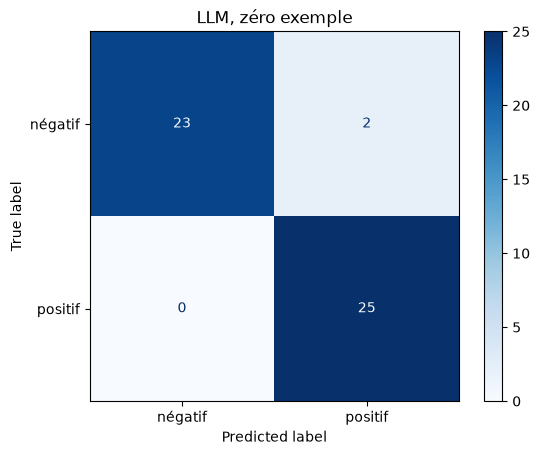

[vrai : négatif] Une sorte de sous Uggly Betty, pas toujours très drôle, mais l'ensemble reste plutôt sympathique.

[vrai : négatif] Un film typique des charlots avec des moments amusants et d'autres franchement lourds. Le film garde tout de même un ton sympathique et bon enfant.



In [21]:
# TODO : évaluation du LLM et erreurs
print("exactitude :", round(accuracy_score(test["sentiment"], pred_llm), 3))
print(classification_report(test["sentiment"], pred_llm, digits=3))
ConfusionMatrixDisplay.from_predictions(test["sentiment"], pred_llm, cmap="Blues")
plt.title("LLM, zéro exemple")
plt.show()
erreurs = test[test["sentiment"] != pd.Series(pred_llm)]
for texte, vrai in erreurs[["critique", "sentiment"]].itertuples(index=False):
    print(f"[vrai : {vrai}] {texte}\n")

✅ **Éléments de réponse**

- Sans **aucun exemple d'entraînement**, le LLM classe correctement **96 %** des critiques (48 sur 50) avec `ministral-8b-latest` à température 0 (exécution du 2 novembre 2026). Le chiffre peut varier d'un ou deux points selon la version du modèle. Toutes les critiques qu'il dit négatives le sont (précision de 1 pour « négatif ») ; il en manque deux (rappel de 0,92).
- Les deux erreurs portent sur des critiques **mitigées**, classées négatives par leur auteur mais qui se terminent sur une note aimable (« l'ensemble reste plutôt sympathique », « un ton sympathique et bon enfant »). Un humain hésiterait aussi : l'étiquette d'origine vient de la note donnée par l'auteur, que le texte seul ne reflète pas toujours.
- Sur 50 critiques, une erreur de plus ou de moins fait varier l'exactitude de 2 points : ce chiffre est **imprécis**, à prendre comme un ordre de grandeur.

**6.3** Entraînez maintenant un modèle classique sur les 5 000 critiques de `data/allocine_train.csv` : un pipeline `TfidfVectorizer()` suivi d'une `LogisticRegression(max_iter=1000)`. Mesurez le temps d'entraînement et le temps de prédiction des 50 critiques de `test`, puis son exactitude et son rapport de classification.

In [22]:
# TODO : TF-IDF + régression logistique
train = pd.read_csv("data/allocine_train.csv")
logreg = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
debut = time.perf_counter()
logreg.fit(train["critique"], train["sentiment"])
duree_fit = time.perf_counter() - debut
debut = time.perf_counter()
pred_logreg = logreg.predict(test["critique"])
duree_pred = time.perf_counter() - debut
print(f"entraînement : {duree_fit:.1f} s | prédiction des 50 critiques : {duree_pred * 1000:.1f} ms")
print("exactitude :", round(accuracy_score(test["sentiment"], pred_logreg), 3))
print(classification_report(test["sentiment"], pred_logreg, digits=3))

entraînement : 0.1 s | prédiction des 50 critiques : 1.1 ms
exactitude : 0.82
              precision    recall  f1-score   support

     négatif      0.808     0.840     0.824        25
     positif      0.833     0.800     0.816        25

    accuracy                          0.820        50
   macro avg      0.821     0.820     0.820        50
weighted avg      0.821     0.820     0.820        50



**6.4** Quels mots poussent le plus vers « positif » et vers « négatif » ? Affichez les 10 mots de plus grand coefficient et les 10 de plus petit (`logreg[0].get_feature_names_out()` et `logreg[-1].coef_[0]` ; la classe « positif » est la deuxième, `logreg[-1].classes_`).

In [23]:
# TODO : les mots les plus influents
mots = pd.Series(logreg[-1].coef_[0], index=logreg[0].get_feature_names_out()).sort_values()
print(logreg[-1].classes_)
print("vers négatif :", mots.head(10).index.tolist())
print("vers positif :", mots.tail(10).index.tolist()[::-1])

['négatif' 'positif']
vers négatif : ['mauvais', 'pas', 'rien', 'nul', 'ennuyeux', 'mal', 'intérêt', 'scénario', 'navet', 'trop']
vers positif : ['excellent', 'bon', 'très', 'magnifique', 'super', 'voir', 'beau', 'excellente', 'et', 'bien']


**6.5** Synthèse. Remplissez le tableau comparatif suivant (exactitude, temps par critique, coût, données nécessaires, confidentialité), puis répondez : pour le site de cinéma, qui reçoit 20 000 critiques par mois, que recommanderiez-vous ? Et pour une petite entreprise qui veut classer, dès demain, les avis sur ses produits en cinq catégories qu'elle vient d'inventer, sans aucune donnée étiquetée ?

✅ **Éléments de réponse**

| Critère | LLM (`ministral-8b-latest`) | TF-IDF + régression logistique |
|---|---|---|
| Exactitude sur les 50 critiques | 96 % | 82 % |
| Temps par critique | environ 0,4 s (appel réseau) | de l'ordre de la dizaine de microsecondes |
| Coût | environ 0,3 $ par mois (partie 2) | quasi nul une fois entraîné |
| Données étiquetées | aucune | 5 000 critiques |
| Confidentialité | les critiques partent chez Mistral | tout reste sur le serveur du site |
| Reproductibilité | approximative | totale |

- Le LLM est **meilleur** sur ce jeu de test (2 erreurs contre 9), sans aucun entraînement : il comprend les tournures (la négation, les avis nuancés, l'ironie) que le sac de mots du TF-IDF ignore. Avec 50 critiques, l'écart reste à confirmer sur un jeu plus grand, mais il est net.
- La régression logistique est **des milliers de fois plus rapide** (0,1 s d'entraînement, 1 ms pour les 50 prédictions), gratuite, reproductible et explicable : les mots de 6.4 (« mauvais », « nul », « ennuyeux », « navet » côté négatif ; « excellent », « magnifique », « super » côté positif) sont ceux qu'on attendait. On y voit aussi ses limites : « pas » pousse vers négatif quel que soit le mot qui suit, et « scénario » aussi, simplement parce que les critiques négatives en parlent plus souvent.
- **Pour le site de cinéma**, le choix se discute. Le LLM est plus juste et son coût (moins d'un dollar par mois) est négligeable pour ce volume ; il permet en plus d'extraire les points forts et faibles (partie 5), ce qu'aucun classifieur simple ne sait faire. Le modèle classique reste pertinent si les critiques ne doivent pas quitter les serveurs du site, si le volume explose ou s'il faut une réponse instantanée ; on pourrait aussi l'améliorer en l'entraînant sur bien plus que 5 000 critiques.
- **Pour la petite entreprise** sans données étiquetées, avec des catégories nouvelles, le LLM est le bon outil : il fonctionne dès demain avec un prompt. Elle pourra plus tard se servir de ses prédictions, vérifiées, pour entraîner un modèle classique si le volume grandit.

## Partie 7 — *Facultatif* : few-shot, autres modèles, extraction d'information

**7.1** *Few-shot*. Écrivez une fonction `prompt_few_shot(texte)` qui reprend le prompt précis de 4.3 en ajoutant, avant la critique à classer, **quatre exemples résolus** tirés de `train` (deux positifs, deux négatifs), sous forme de paires de messages `user` / `assistant`. Classez à nouveau les 50 critiques. L'exactitude change-t-elle ? Combien de tokens coûte chaque appel en plus ?

In [24]:
# TODO : few-shot avec quatre exemples
exemples = pd.concat([train[train["sentiment"] == s].head(2) for s in ["positif", "négatif"]])


def prompt_few_shot(texte):
    messages = prompt_precis(texte)[:1]
    for ex_texte, ex_sentiment in exemples[["critique", "sentiment"]].itertuples(index=False):
        messages.append({"role": "user", "content": "Classe la critique ci-dessous. Réponds uniquement par un mot : positif ou négatif.\n"
                                                    f"<critique>\n{ex_texte}\n</critique>"})
        messages.append({"role": "assistant", "content": f'{{"sentiment": "{ex_sentiment}"}}'})
    return messages + prompt_precis(texte)[1:]


pred_few = []
for t in test["critique"]:
    reponse = appeler(prompt_few_shot(t), response_format=Sentiment, temperature=0)
    pred_few.append(reponse.choices[0].message.parsed.sentiment)
print("exactitude few-shot :", round(accuracy_score(test["sentiment"], pred_few), 3))
for nom, construire in [("zéro exemple", prompt_precis), ("few-shot", prompt_few_shot)]:
    print(f"tokens envoyés pour la première critique, {nom} :", compter_tokens_messages(construire(test["critique"][0])))

exactitude few-shot : 0.96


tokens envoyés pour la première critique, zéro exemple : 134


tokens envoyés pour la première critique, few-shot : 685


✅ **Éléments de réponse**

- Sur une tâche aussi simple, les exemples ne changent rien ici (96 % dans les deux cas) : le modèle savait déjà ce qu'est une critique positive. Le few-shot est surtout utile quand la tâche ou le format sont **inhabituels** (des catégories propres à une entreprise, un style de réponse particulier).
- En revanche, chaque appel envoie environ **cinq fois plus de tokens** (134 contre 685 pour la première critique), car les quatre exemples sont renvoyés à chaque critique : le coût augmente d'autant, pour rien sur cette tâche.

**7.2** *Autres modèles*. Les fonctions `classer` et `analyser` acceptent un paramètre `modele`. Classez les 50 critiques avec `ministral-3b-latest` (plus petit) et `ministral-14b-latest` (plus gros), en mesurant l'exactitude et le temps. Le plus gros modèle est-il toujours le meilleur choix ? (Avec l'offre gratuite, `ministral-14b-latest` n'accepte qu'une trentaine de requêtes par minute : la boucle prend environ deux minutes.)

*Avec Ollama, utilisez les noms de vos modèles locaux, par exemple `ministral-3:3b`.*

In [25]:
# TODO : comparer plusieurs tailles de modèle
for modele in ["ministral-3b-latest", "ministral-14b-latest"]:
    debut = time.perf_counter()
    pred = [classer(t, modele=modele) for t in test["critique"]]
    duree = time.perf_counter() - debut
    print(f"{modele} : exactitude {accuracy_score(test['sentiment'], pred):.2f}, {duree / len(pred):.2f} s par critique")

ministral-3b-latest : exactitude 0.92, 0.41 s par critique


Trop de requêtes : nouvel essai dans 1 s


Trop de requêtes : nouvel essai dans 2 s


ministral-14b-latest : exactitude 0.94, 1.24 s par critique


✅ **Éléments de réponse**

Sur cette tâche facile, les trois tailles de modèle obtiennent des exactitudes **proches** : 92 % pour le 3b, 96 % pour le 8b, 94 à 96 % pour le 14b selon les exécutions (oui, à température 0 : le résultat n'est pas strictement reproductible), soit deux critiques d'écart au plus, ce qui n'est pas significatif sur 50. Le plus gros n'apporte rien ici, et il est plus cher et plus lent (sur l'offre gratuite, sa limite de débit fait passer le temps moyen à près de 2 s par critique). On choisit le **plus petit modèle qui suffit** à la tâche ; les gros modèles se réservent aux tâches difficiles (raisonnement, longs documents, extraction complexe).

**7.3** *Extraction d'information*. Un service client reçoit des messages comme ceux ci-dessous. Écrivez une classe `Reclamation` avec les champs `commande` (numéro, **facultatif** : `int | None = None`), `produit`, `probleme` et `demande` (`Literal["remboursement", "échange", "réparation", "autre"]`), puis extrayez les informations des deux messages. Que se passe-t-il pour le numéro de commande du second message ? Retirez la valeur par défaut `None` et le type `None` du champ `commande` : que fait alors le modèle ?

In [26]:
messages_clients = [
    "Bonjour, ma trottinette (commande 58213) est arrivée avec la batterie cassée. Je demande un remboursement. Camille M.",
    "Le casque audio que j'ai reçu hier grésille côté gauche. Pouvez-vous me l'échanger contre un neuf ? Merci, Sacha",
]

In [27]:
# TODO : extraction d'information avec un champ facultatif
class Reclamation(BaseModel):
    commande: int | None = Field(default=None, description="numéro de commande s'il est indiqué dans le message")
    produit: str
    probleme: str = Field(description="le problème, en quelques mots")
    demande: Literal["remboursement", "échange", "réparation", "autre"]


for message in messages_clients:
    reponse = appeler(
        [{"role": "user", "content": f"Extrais les informations de ce message de client :\n<message>\n{message}\n</message>"}],
        response_format=Reclamation, temperature=0)
    print(reponse.choices[0].message.parsed)

commande=58213 produit='trottinette' probleme='batterie cassée' demande='remboursement'


commande=None produit='casque audio' probleme='grésille côté gauche' demande='échange'


✅ **Éléments de réponse**

- Les deux messages sont correctement transformés en objets : produit, problème et type de demande (remboursement pour le premier, échange pour le second).
- Pour le second message, qui ne contient aucun numéro, le champ facultatif vaut `None` : le modèle a le droit de dire « absent ».
- Si l'on rend le champ obligatoire (`commande: int`), le schéma **force** le modèle à écrire un entier : avec `ministral-8b-latest`, il répond `commande=0`, d'autres modèles inventent un numéro plausible. Un programme prendrait cette valeur pour un vrai numéro : c'est une **erreur provoquée par le schéma**. Il faut toujours prévoir un champ facultatif quand l'information peut manquer.

## Pour aller plus loin (bonus)

**Le *streaming*.** Avec `stream=True`, l'API envoie la réponse morceau par morceau, au fur et à mesure de sa génération, comme dans ChatGPT. Essayez :

```python
flux = client.chat.completions.create(model=MODELE, stream=True,
    messages=[{"role": "user", "content": "Raconte en dix lignes l'histoire d'un robot cinéphile."}])
for morceau in flux:
    print(morceau.choices[0].delta.content or "", end="", flush=True)
```

Dans une application web, c'est ce qui permet d'afficher la réponse sans attendre qu'elle soit complète : pensez-y pour votre projet.